# 01 — Export select-window pool12 data (Shalow)

Pipeline step 1: export **one row per noon snapshot**, each with **all 12 catalog windows** from `Magic_window/window_selection.ipynb`.

**Settings**
- **`EXPORT_KEY = select_window_12`** → data under `Shalow/data/select_window_12/`, logs `export_select_window_12_*.log`
- `DT = 360`, 3 cond + 1 pred, u+v
- **`CROPS_PER_ANCHOR = 1`** → 1 export row per snapshot (~3652 rows), no duplicate rows per anchor
- **Window pool:** `_sims_pool_k1.npy` — shape `(n_snapshots, 12, T, C, 128, 128)`
- **Training k (spatial):** set `TRAIN_SLOTS_PER_EPOCH` to **1, 2, or 6** in the train notebook = random picks from 12 windows each epoch (default export note: 6)
- **Validation / test:** **all 12 windows** per snapshot → per-window RMSE
- **Mask filter:** drop if land/coastal invalid **≥ 40%** (`MAX_MASK_FRAC = 0.4`)
- **Test:** 2023 noon full year, 1 row per anchor, same 12-window pool
- **Device:** `CUDA_VISIBLE_DEVICES=7`

Catalog: `Magic_window/window_catalog.py` (`magic_window_12`).


In [1]:
import json
import os
import sys
from dataclasses import asdict
from pathlib import Path

import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd().resolve()
SHALOW_DIR = NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Shalow" else NOTEBOOK_DIR / "Shalow"
ROOT = SHALOW_DIR.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if str(SHALOW_DIR) not in sys.path:
    sys.path.insert(0, str(SHALOW_DIR))

DATA_DIR = SHALOW_DIR / "data"
LOG_DIR = SHALOW_DIR / "logs"
for _d in (DATA_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

from src.data.dataloaders.guiana_margem_tensor import GuianaDataloader
from src.export.fix_window_export import candidate_indices_for_hour
from src.export.random_window_export import (
    RandomWindowExportConfig,
    export_wants_fresh_start,
    plan_multi_crop_export,
    run_export,
)
from window_paths import export_manifest_path, pool_prefix, test_prefix, window_data_dir
from Magic_window.window_catalog import CATALOG_ID, catalog_manifest, get_resolved_catalog


In [2]:
os.environ["CUDA_VISIBLE_DEVICES"] = "7"

ZARR_PATH = os.getenv(
    "GUIANA_ZARR_PATH",
    "s3://oceangen-data/margem_equatorial_tensor.zarr",
)

EXPORT_KEY = "magic_pool12_128"
CATALOG_ID = CATALOG_ID  # magic_window_12 from window_selection.ipynb
WINDOW_MODE = "catalog"
CROP_HEIGHT = 128
CROP_WIDTH = 128

DT = 360
CONDITIONING_STEPS = 3
FORECAST_STEPS = 1
EXPORT_COMPONENTS = ("uv",)

WINDOW_DATA_DIR = window_data_dir(DATA_DIR, EXPORT_KEY)
POOL_DATA_PREFIX_BASE = pool_prefix(DATA_DIR, EXPORT_KEY, dt=DT)
TEST_DATA_PREFIX_BASE = test_prefix(DATA_DIR, EXPORT_KEY, dt=DT)
EXPORT_MANIFEST_PATH = export_manifest_path(DATA_DIR, EXPORT_KEY)


def _component_export_settings(component: str, base: str | None = None):
    if component == "uv":
        base = base or POOL_DATA_PREFIX_BASE
        return base, ("u", "v"), (0, 1)
    raise ValueError(f"Unknown component {component!r}; use 'uv'")


PREVIEW_COMPONENT = EXPORT_COMPONENTS[0]
OUTPUT_PREFIX, CHANNEL_NAMES, TARGET_CHANNEL_INDICES = _component_export_settings(PREVIEW_COMPONENT)

SEED = 42
N_JOBS = 30
MAX_MASK_FRAC = 0.4  # reject crop when masked fraction >= 40%
MAX_CROP_ATTEMPTS = 200
HOUR_OF_DAY = 12
CROPS_PER_ANCHOR = 1  # 1 export row per noon snapshot (no duplicate rows per anchor)

EXPORT_WINDOW_POOL = True
N_WINDOWS_PER_SAMPLE = 12
TRAIN_CROPS_FOR_WINDOW_POOL = (1,)  # single pool: _sims_pool_k1.npy
TRAIN_SLOTS_PER_EPOCH = 6  # default training note; train notebook sets 1, 2, or 6
TRAIN_SLOTS_OPTIONS = (1, 2, 6)  # k windows per snapshot per epoch -> train rows = n_snapshots * k
EXPORT_EPOCH_WINDOWS = False

N_EXPORT_EPOCHS = 100
RANDOM_CROP_SEED = 42
VAL_SPLIT = 0.3
VAL_SPLIT_MODE = "random"
VAL_SPLIT_SEED = 42
TRAIN_CROPS_FOR_EPOCH_WINDOWS = (1,)

N_SAMPLES_TO_GEN = 8_000  # cap rows (= n_anchors * CROPS_PER_ANCHOR; full noon pool ≈ 3652)
START_TIME = "2013-01-01"
END_TIME = "2022-12-31"

CATALOG = get_resolved_catalog(CATALOG_ID)
assert len(CATALOG) == N_WINDOWS_PER_SAMPLE

WINDOW_DATA_DIR.mkdir(parents=True, exist_ok=True)


## Catalog overview — 12 selected windows

Run after the config cell. Overlays all export windows from `window_selection.ipynb` on the full-domain bathymetry (slot 0..11 = pool indices for per-window loss).

Saved: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/catalog_overview.png


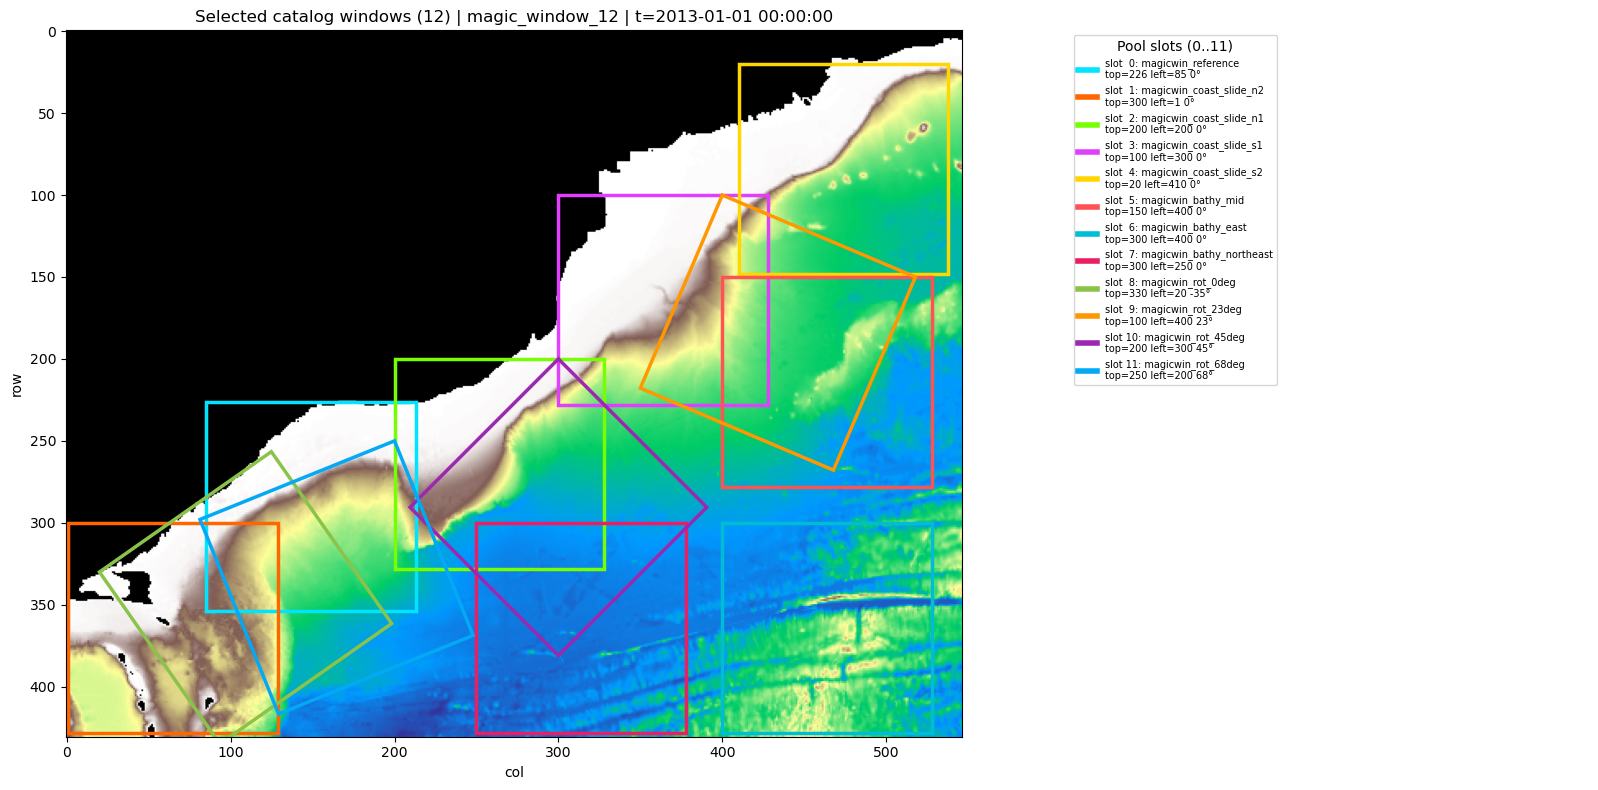

In [3]:
%matplotlib inline

import importlib.util
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon, Rectangle

from src.data.useful_transforms import rotated_window_corners

# Reuse bathymetry / outline helpers from window_selection.ipynb
_mw = ROOT / "Magic_window"
_setup_spec = importlib.util.spec_from_file_location(
    "window_selection_setup", _mw / "window_selection_setup.py"
)
_wsetup = importlib.util.module_from_spec(_setup_spec)
_setup_spec.loader.exec_module(_wsetup)
_wsetup.ensure_setup()

OVERVIEW_COLORS = [
    "#00E5FF", "#FF6600", "#76FF03", "#E040FB", "#FFD600", "#FF5252",
    "#00BCD4", "#E91E63", "#8BC34A", "#FF9800", "#9C27B0", "#03A9F4",
]
for i, spec in enumerate(CATALOG):
    spec["color"] = OVERVIEW_COLORS[i % len(OVERVIEW_COLORS)]


def _outline_window(ax, spec):
    t, l = spec["window_top"], spec["window_left"]
    h, w, a = spec["crop_height"], spec["crop_width"], spec["window_angle"]
    if a == 0:
        ax.add_patch(
            Rectangle(
                (l, t), w, h, fill=False, edgecolor=spec["color"], lw=2.5,
                label=spec["export_key"],
            )
        )
    else:
        ax.add_patch(
            Polygon(
                rotated_window_corners(t, l, h, a, w),
                fill=False,
                edgecolor=spec["color"],
                lw=2.5,
                label=spec["export_key"],
            )
        )


fields, t_str = _wsetup.load_fields(0)
bathy = fields["bathymetry"]
b_ok = bathy[np.isfinite(bathy) & (bathy != 0)]
b_vmin, b_vmax = (float(b_ok.min()), float(b_ok.max())) if b_ok.size else (None, None)

fig, (ax_map, ax_leg) = plt.subplots(
    1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [3, 1.4]}
)
ax_map.imshow(
    _wsetup.mask_land(bathy),
    cmap=_wsetup.bathymetry_cmap(),
    vmin=b_vmin,
    vmax=b_vmax,
    origin="upper",
)
# Magic reference window (dashed)
ax_map.add_patch(
    Rectangle(
        (_wsetup.MAGIC_LEFT, _wsetup.MAGIC_TOP),
        _wsetup.MAGIC_W,
        _wsetup.MAGIC_H,
        fill=False,
        edgecolor="#FF4444",
        lw=1.5,
        ls="--",
    )
)
for spec in CATALOG:
    _outline_window(ax_map, spec)
ax_map.set_title(
    f"Selected catalog windows ({len(CATALOG)}) | {CATALOG_ID} | t={t_str}",
    fontsize=12,
)
ax_map.set_xlabel("col")
ax_map.set_ylabel("row")

ax_leg.axis("off")
handles = [
    Line2D(
        [0], [0], color=spec["color"], lw=4,
        label=(
            f"slot {spec['slot']:2d}: {spec['export_key']}\n"
            f"top={spec['window_top']} left={spec['window_left']} "
            f"{spec['window_angle']:.0f}°"
        ),
    )
    for spec in CATALOG
]
ax_leg.legend(handles=handles, loc="upper left", fontsize=7, title="Pool slots (0..11)")
plt.tight_layout()

overview_path = WINDOW_DATA_DIR / "catalog_overview.png"
fig.savefig(overview_path, dpi=150, bbox_inches="tight")
print(f"Saved: {overview_path}")
plt.show()

In [4]:
base_kwargs = dict(
    path=ZARR_PATH,
    dt=DT,
    conditioning_steps=CONDITIONING_STEPS,
    forecast_steps=FORECAST_STEPS,
    start_time=START_TIME,
    end_time=END_TIME,
)

print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))
print("Catalog:", CATALOG_ID, "|", len(CATALOG), "windows from window_selection.ipynb")
for spec in CATALOG:
    print(
        f"  slot {spec['slot']:2d}: {spec['export_key']:<28} "
        f"top={spec['window_top']:3d} left={spec['window_left']:3d} angle={spec['window_angle']:6.1f}°"
    )

print("Opening Zarr:", ZARR_PATH)
dataset = GuianaDataloader(**base_kwargs, transform=None)
info = dataset.info()
candidate_idx = candidate_indices_for_hour(dataset, HOUR_OF_DAY)

pool_anchors, pool_zarr_idx, pool_crop_slots = plan_multi_crop_export(
    candidate_idx,
    n_samples_to_gen=N_SAMPLES_TO_GEN,
    crops_per_anchor=CROPS_PER_ANCHOR,
    seed=SEED,
)
n_anchors = len(pool_anchors)
n_rows = len(pool_zarr_idx)

export_manifest = {
    "export_key": EXPORT_KEY,
    "window_data_dir": str(WINDOW_DATA_DIR),
    "window_mode": WINDOW_MODE,
    "catalog_id": CATALOG_ID,
    "catalog": catalog_manifest(CATALOG),
    "mode": "catalog_pool_export",
    "sample_seed": SEED,
    "n_pool": int(len(candidate_idx)),
    "n_anchors": int(n_anchors),
    "crops_per_anchor": int(CROPS_PER_ANCHOR),
    "n_rows": int(n_rows),
    "start_time": START_TIME,
    "end_time": END_TIME,
    "hour_of_day": HOUR_OF_DAY,
    "crop_height": CROP_HEIGHT,
    "crop_width": CROP_WIDTH,
    "max_mask_frac": MAX_MASK_FRAC,
    "pool_data_prefix_base": POOL_DATA_PREFIX_BASE,
    "train_val_split_note": "70/30 split at training time",
    "export_window_pool": EXPORT_WINDOW_POOL,
    "n_windows_per_sample": N_WINDOWS_PER_SAMPLE,
    "train_crops_for_window_pool": list(TRAIN_CROPS_FOR_WINDOW_POOL),
    "train_slots_per_epoch": TRAIN_SLOTS_PER_EPOCH,
    "train_slots_options": list(TRAIN_SLOTS_OPTIONS),
    "train_slots_note": "k=1,2,6 means TRAIN_SLOTS_PER_EPOCH in train notebook (spatial picks from 12)",
    "random_crop_seed": RANDOM_CROP_SEED,
    "cuda_visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES"),
    "zarr_indices": pool_anchors.tolist(),
}
EXPORT_MANIFEST_PATH.write_text(json.dumps(export_manifest, indent=2))

print("Valid samples:", len(dataset))
print("After hour filter:", len(candidate_idx), "| HOUR_OF_DAY =", HOUR_OF_DAY)
print(
    f"Pool plan: {n_anchors} noon anchors × {CROPS_PER_ANCHOR} crops = {n_rows} export rows "
    f"(seed={SEED}) → {POOL_DATA_PREFIX_BASE}"
)
print("Export manifest:", EXPORT_MANIFEST_PATH)
print("Grid (H, W):", info["space"]["height"], info["space"]["width"])
print(
    f"Window pool: {N_WINDOWS_PER_SAMPLE} catalog windows/row, "
    f"{n_rows} snapshots (CROPS_PER_ANCHOR={CROPS_PER_ANCHOR}) → _sims_pool_k1.npy"
)
print(
    f"Training spatial k options: {list(TRAIN_SLOTS_OPTIONS)} "
    f"(TRAIN_SLOTS_PER_EPOCH in train notebook; default note={TRAIN_SLOTS_PER_EPOCH})"
)
print("Val/test: all 12 windows per snapshot (no random slot)")
if n_rows < N_SAMPLES_TO_GEN:
    print(
        f"NOTE: {n_rows} rows < N_SAMPLES_TO_GEN={N_SAMPLES_TO_GEN} "
        f"(limited by {len(candidate_idx)} noon anchors × {CROPS_PER_ANCHOR})"
    )


CUDA_VISIBLE_DEVICES: 7
Catalog: magic_window_12 | 12 windows from window_selection.ipynb
  slot  0: magicwin_reference           top=226 left= 85 angle=   0.0°
  slot  1: magicwin_coast_slide_n2      top=300 left=  1 angle=   0.0°
  slot  2: magicwin_coast_slide_n1      top=200 left=200 angle=   0.0°
  slot  3: magicwin_coast_slide_s1      top=100 left=300 angle=   0.0°
  slot  4: magicwin_coast_slide_s2      top= 20 left=410 angle=   0.0°
  slot  5: magicwin_bathy_mid           top=150 left=400 angle=   0.0°
  slot  6: magicwin_bathy_east          top=300 left=400 angle=   0.0°
  slot  7: magicwin_bathy_northeast     top=300 left=250 angle=   0.0°
  slot  8: magicwin_rot_0deg            top=330 left= 20 angle= -35.0°
  slot  9: magicwin_rot_23deg           top=100 left=400 angle=  23.0°
  slot 10: magicwin_rot_45deg           top=200 left=300 angle=  45.0°
  slot 11: magicwin_rot_68deg           top=250 left=200 angle=  68.0°
Opening Zarr: s3://oceangen-data/margem_equatorial_tensor.

Valid samples: 87648
After hour filter: 3652 | HOUR_OF_DAY = 12
Pool plan: 3652 noon anchors × 1 crops = 3652 export rows (seed=42) → /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_13_22_uv_dt360
Export manifest: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_13_22_export.json
Grid (H, W): 431 547
Window pool: 12 catalog windows/row, 3652 snapshots (CROPS_PER_ANCHOR=1) → _sims_pool_k1.npy
Training spatial k options: [1, 2, 6] (TRAIN_SLOTS_PER_EPOCH in train notebook; default note=6)
Val/test: all 12 windows per snapshot (no random slot)
NOTE: 3652 rows < N_SAMPLES_TO_GEN=8000 (limited by 3652 noon anchors × 1)


## Parallel export (resumable)

**Stop a running background export:**

```bash
# find PID
pgrep -af 'export_random_window_data.py.*magic_pool12_128'

# stop it (replace PID)
kill <PID>
# if it does not stop:
kill -9 <PID>
```

**Fresh re-export:** set `RESUME = False` in the next cell (uses `--no-resume`, clears old `.npy` / pool files).

- **3652 rows** (1 per snapshot) → `_sims_pool_k1.npy` with 12 catalog windows each
- After merge, window pool runs automatically

```bash
CUDA_VISIBLE_DEVICES=7 python scripts/export_random_window_data.py \
  --output-prefix Shalow/data/magic_pool12_128/sample_13_22_uv_dt360 --no-resume
```


In [5]:
import subprocess

DETACHED = True
CHUNK_SIZE = 100
RESUME = False  # fresh re-export: clears old outputs and uses --no-resume


def _run_one_export(
    output_prefix: str,
    channel_names: tuple[str, ...],
    target_channel_indices: tuple[int, ...],
    *,
    start_time: str | None = None,
    end_time: str | None = None,
    n_samples_to_gen: int | None = None,
    crops_per_anchor: int | None = None,
    fixed_dataset_indices: tuple[int, ...] | None = None,
):
    export_config = RandomWindowExportConfig(
        zarr_path=ZARR_PATH,
        dt=DT,
        conditioning_steps=CONDITIONING_STEPS,
        forecast_steps=FORECAST_STEPS,
        crop_height=CROP_HEIGHT,
        crop_width=CROP_WIDTH,
        seed=SEED,
        n_jobs=N_JOBS,
        max_mask_frac=MAX_MASK_FRAC,
        max_crop_attempts=MAX_CROP_ATTEMPTS,
        hour_of_day=HOUR_OF_DAY,
        start_time=start_time or START_TIME,
        end_time=end_time or END_TIME,
        output_prefix=output_prefix,
        n_samples_to_gen=n_samples_to_gen if n_samples_to_gen is not None else N_SAMPLES_TO_GEN,
        crops_per_anchor=crops_per_anchor if crops_per_anchor is not None else CROPS_PER_ANCHOR,
        chunk_size=CHUNK_SIZE,
        channel_names=channel_names,
        target_channel_indices=target_channel_indices,
        fixed_dataset_indices=fixed_dataset_indices,
        export_key=EXPORT_KEY,
        export_epoch_windows=EXPORT_EPOCH_WINDOWS,
        export_window_pool=EXPORT_WINDOW_POOL,
        n_windows_per_sample=N_WINDOWS_PER_SAMPLE,
        train_crops_for_window_pool=TRAIN_CROPS_FOR_WINDOW_POOL,
        train_slots_per_epoch=TRAIN_SLOTS_PER_EPOCH,
        n_export_epochs=N_EXPORT_EPOCHS,
        random_crop_seed=RANDOM_CROP_SEED,
        val_split=VAL_SPLIT,
        val_split_mode=VAL_SPLIT_MODE,
        val_split_seed=VAL_SPLIT_SEED,
        train_crops_for_epoch_windows=TRAIN_CROPS_FOR_EPOCH_WINDOWS,
        window_mode=WINDOW_MODE,
        catalog_id=CATALOG_ID,
    )

    config_path = Path(f"{output_prefix}_export_config.json")
    config_dict = asdict(export_config)
    config_dict["window_mode"] = WINDOW_MODE
    config_path.write_text(json.dumps(config_dict, indent=2, default=str))
    print(f"Wrote config: {config_path}")

    fresh_start = export_wants_fresh_start(export_config, resume=RESUME)

    if DETACHED:
        log_path = LOG_DIR / f"export_{EXPORT_KEY}_{Path(output_prefix).name}.log"
        cmd = [
            sys.executable,
            str(ROOT / "scripts/export_random_window_data.py"),
            "--output-prefix",
            output_prefix,
        ]
        if fresh_start:
            cmd.append("--no-resume")
            if log_path.exists():
                log_path.unlink()
                print(f"Cleared log: {log_path}")
        log_mode = "w" if fresh_start else "a"
        export_env = os.environ.copy()
        export_env["CUDA_VISIBLE_DEVICES"] = "7"
        with open(log_path, log_mode) as log_file:
            proc = subprocess.Popen(
                cmd,
                stdout=log_file,
                stderr=subprocess.STDOUT,
                start_new_session=True,
                cwd=ROOT,
                env=export_env,
            )
        print(f"Started background export PID {proc.pid} -> {output_prefix}")
        if fresh_start:
            print("Fresh export (log cleared, partial state reset if config changed)")
        else:
            print(f"Resuming export (appending to {log_path})")
        print(f"Log: {log_path}")
        print(f"Monitor: tail -f {log_path}")
        print(
            f"Resume: python scripts/export_random_window_data.py --output-prefix {output_prefix}"
        )
    else:
        run_export(export_config, resume=not fresh_start)


for component in EXPORT_COMPONENTS:
    pool_pfx, ch_names, tgt_idx = _component_export_settings(component, POOL_DATA_PREFIX_BASE)
    print(
        f"\n=== Pool export: {component} -> {pool_pfx} "
        f"({n_anchors} anchors × {CROPS_PER_ANCHOR} = {n_rows} rows) ==="
    )
    _run_one_export(
        pool_pfx,
        ch_names,
        tgt_idx,
        n_samples_to_gen=n_rows,
        crops_per_anchor=CROPS_PER_ANCHOR,
        fixed_dataset_indices=tuple(int(x) for x in pool_anchors),
    )



=== Pool export: uv -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_13_22_uv_dt360 (3652 anchors × 1 = 3652 rows) ===
Wrote config: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_13_22_uv_dt360_export_config.json
Cleared log: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/logs/export_magic_pool12_128_sample_13_22_uv_dt360.log
Started background export PID 4172276 -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_13_22_uv_dt360
Fresh export (log cleared, partial state reset if config changed)
Log: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/logs/export_magic_pool12_128_sample_13_22_uv_dt360.log
Monitor: tail -f /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/logs/export_magic_pool12_128_sample_13_22_uv_dt360.log
Resume: python scripts/export_random_window_data.py --output-prefix /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/s

## 2023 test export (rollout holdout)


In [6]:
TEST_START_TIME = "2023-01-01"
TEST_END_TIME = "2023-12-31"
TEST_EXPORT_ALL = True

test_kwargs = dict(
    path=ZARR_PATH,
    dt=DT,
    conditioning_steps=CONDITIONING_STEPS,
    forecast_steps=FORECAST_STEPS,
    start_time=TEST_START_TIME,
    end_time=TEST_END_TIME,
)
test_dataset = GuianaDataloader(**test_kwargs, transform=None)
test_candidate_idx = candidate_indices_for_hour(test_dataset, HOUR_OF_DAY)
print(f"2023 test pool: {len(test_candidate_idx)} starts | HOUR_OF_DAY={HOUR_OF_DAY}")
test_n = len(test_candidate_idx) if TEST_EXPORT_ALL else min(N_SAMPLES_TO_GEN, len(test_candidate_idx))
print(f"Will export: {test_n} test sequences")

for component in EXPORT_COMPONENTS:
    test_pfx, test_ch_names, test_tgt_idx = _component_export_settings(
        component, base=TEST_DATA_PREFIX_BASE
    )
    print(f"\n=== 2023 test export: {component} -> {test_pfx} ===")
    _run_one_export(
        test_pfx,
        test_ch_names,
        test_tgt_idx,
        start_time=TEST_START_TIME,
        end_time=TEST_END_TIME,
        n_samples_to_gen=test_n,
        crops_per_anchor=1,
        fixed_dataset_indices=tuple(int(x) for x in test_candidate_idx) if TEST_EXPORT_ALL else None,
    )


2023 test pool: 319 starts | HOUR_OF_DAY=12
Will export: 319 test sequences

=== 2023 test export: uv -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_23_uv_dt360 ===
Wrote config: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_23_uv_dt360_export_config.json
Cleared log: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/logs/export_magic_pool12_128_sample_23_uv_dt360.log
Started background export PID 4172645 -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/data/magic_pool12_128/sample_23_uv_dt360
Fresh export (log cleared, partial state reset if config changed)
Log: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/logs/export_magic_pool12_128_sample_23_uv_dt360.log
Monitor: tail -f /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Shalow/logs/export_magic_pool12_128_sample_23_uv_dt360.log
Resume: python scripts/export_random_window_data.py --output-prefix /opt/dlami/nvme/tmp_storage/LCADAME/hamid_cop